In [1]:
# ============================================================
# CELL 1 ▸ Imports
# ============================================================
import subprocess, sys
for pkg in ['tensorflow','torch','torchaudio','librosa',
            'numpy','pandas','scipy','matplotlib','seaborn',
            'scikit-learn','tqdm','soundfile']:
    imp = 'sklearn' if pkg=='scikit-learn' else pkg
    try: __import__(imp)
    except ImportError:
        subprocess.check_call([sys.executable,'-m','pip','install',
                               '-q',pkg],
                              stdout=subprocess.DEVNULL,
                              stderr=subprocess.DEVNULL)

import os, gc, json, time, zipfile, warnings
from concurrent.futures import ThreadPoolExecutor, as_completed
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
from scipy import stats as scipy_stats
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torchaudio
import torchaudio.transforms as TA

import librosa
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers

warnings.filterwarnings('ignore')
tf.get_logger().setLevel('ERROR')

# GPU for PyTorch (spec extraction)
TORCH_DEV = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# GPU for TF (training)
TF_GPUS   = tf.config.list_physical_devices('GPU')
strategy  = tf.distribute.MirroredStrategy()

print(f'PyTorch {torch.__version__}  |  torch device : {TORCH_DEV}')
print(f'TF      {tf.__version__}    |  TF GPUs      : {len(TF_GPUS)}')
for g in TF_GPUS: print(f'  {g}')
print('Imports complete.')

PyTorch 2.10.0+cu128  |  torch device : cuda
TF      2.20.0    |  TF GPUs      : 2
  PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
  PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')
Imports complete.


I0000 00:00:1786451869.861532     277 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1786451869.865094     277 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [2]:
# ============================================================
# CELL 2 ▸ Configuration
# ============================================================
# ⚙️  Change FOLDS_CSV and AUDIO_ROOT:
FOLDS_CSV  = '/kaggle/input/datasets/tarek1074/part1-outputs/fold_assignments.csv'
AUDIO_ROOT = ('/kaggle/input/datasets/mlfarhan/audio-classification/audio genre classification'
              '/audio genre classification')

WORK_DIR  = '/kaggle/working'
OUT_DIR   = os.path.join(WORK_DIR, 'part4a')
FIG_DIR   = os.path.join(OUT_DIR,  'figures')
MDL_DIR   = os.path.join(OUT_DIR,  'models')
LOG_DIR   = os.path.join(OUT_DIR,  'logs')
SPE_PATH  = os.path.join(WORK_DIR, 'specs_f16.npy')  # kept in working root (large)
SEG_CSV   = os.path.join(OUT_DIR,  'segments.csv')
for d in [OUT_DIR, FIG_DIR, MDL_DIR, LOG_DIR]:
    os.makedirs(d, exist_ok=True)

# Audio
SR           = 22050
SEG_DUR      = 10
SEG_SAMPLES  = SR * SEG_DUR   # 220,500
N_MELS, N_FFT, HOP = 128, 2048, 512
IMG_H, IMG_W, IMG_C = 128, 128, 3

# Training
N_FOLDS    = 5
EPOCHS     = 80
PATIENCE   = 15
LR_INIT    = 1e-3
SEED       = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

N_GPUS     = strategy.num_replicas_in_sync
BATCH_SIZE = 32 * max(1, N_GPUS)   # 64 total with 2×T4

CLASS_NAMES = [
    'Bangla_Band_Collection','Bangla_ancholik','Bangla_baby_rhymes',
    'Bangla_rabindra_sangeet','Bangla_romantic','Classic_Songs_',
    'Islamic_Melody','Nazrul_Geeti_',
]
CLASS_SHORT = {
    'Bangla_Band_Collection':'Band', 'Bangla_ancholik':'Ancholik',
    'Bangla_baby_rhymes':'Rhymes',   'Bangla_rabindra_sangeet':'Rabindra',
    'Bangla_romantic':'Romantic',    'Classic_Songs_':'Classic',
    'Islamic_Melody':'Islamic',      'Nazrul_Geeti_':'Nazrul',
}
N_CLASSES   = len(CLASS_NAMES)
SHORT_NAMES = [CLASS_SHORT[c] for c in CLASS_NAMES]
le          = LabelEncoder().fit(CLASS_NAMES)
CLASS_PAL   = dict(zip(CLASS_NAMES, sns.color_palette('tab10',8)))

sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi':150,'savefig.dpi':300,
                     'font.size':11,'savefig.bbox':'tight'})

print('Configuration loaded.')
print(f'  N_GPUS={N_GPUS}  BATCH={BATCH_SIZE}  '
      f'EPOCHS={EPOCHS}  PATIENCE={PATIENCE}')
print(f'  SPE_PATH : {SPE_PATH}')

Configuration loaded.
  N_GPUS=2  BATCH=64  EPOCHS=80  PATIENCE=15
  SPE_PATH : /kaggle/working/specs_f16.npy


In [3]:
# ============================================================
# CELL 3 ▸ Segment List  (one row per 10-second clip)
# ============================================================
# Uses torchaudio.info() for duration — works on MP3.
# Loads segments.csv from cache if already valid.

def find_root(base, cls_list):
    for root, dirs, _ in os.walk(base):
        if sum(1 for d in dirs
               if any(c.strip('_ ').lower() in d.strip('_ ').lower()
                      for c in cls_list)) >= 4:
            return root
    return base

def get_duration(fp):
    try:
        info = torchaudio.info(fp)
        d    = info.num_frames / info.sample_rate
        if d > 0: return d
    except Exception: pass
    try:
        import soundfile as sf
        d = sf.info(fp).duration
        if d > 0: return d
    except Exception: pass
    return 0.0

print('Loading fold_assignments.csv ...')
fold_df = pd.read_csv(FOLDS_CSV)

# Remap paths if needed
n_miss = sum(1 for fp in fold_df['filepath'] if not os.path.exists(fp))
if n_miss:
    DR = find_root(AUDIO_ROOT, CLASS_NAMES)
    def remap(fp):
        fn = os.path.basename(fp)
        cl = os.path.basename(os.path.dirname(fp))
        c  = os.path.join(DR, cl, fn)
        return c if os.path.exists(c) else fp
    fold_df['filepath'] = fold_df['filepath'].apply(remap)
    n_miss2 = sum(1 for fp in fold_df['filepath'] if not os.path.exists(fp))
    print(f'  Remapped: {n_miss} → {n_miss2} still missing')
else:
    print(f'  {len(fold_df):,} files | ✅ all found')

# Validate cache
rebuild = True
if os.path.exists(SEG_CSV):
    prev = pd.read_csv(SEG_CSV)
    mx   = prev.groupby('filepath').size().max()
    if mx > 1:
        print(f'  segments.csv valid ({len(prev):,} rows, max {mx}/file) — loading')
        seg_df  = prev
        rebuild = False
    else:
        print('  segments.csv invalid (≤1 seg/file) — rebuilding')
        os.remove(SEG_CSV)
        if os.path.exists(SPE_PATH): os.remove(SPE_PATH)

if rebuild:
    print('Building segment list ...')
    rows, n_fail, n_short = [], 0, 0
    for _, row in tqdm(fold_df.iterrows(), total=len(fold_df),
                       desc='  Files', unit='file'):
        fp  = row['filepath']
        if not os.path.exists(fp): n_fail += 1; continue
        dur = get_duration(fp)
        if dur < 1.0:              n_fail += 1; continue
        n_seg = 1 if dur < SEG_DUR else int(dur // SEG_DUR)
        if dur < SEG_DUR:          n_short += 1
        for i in range(n_seg):
            rows.append({'filepath' : fp,
                         'label'    : row['label'],
                         'label_id' : int(le.transform([row['label']])[0]),
                         'fold'     : int(row['fold']),
                         'seg_idx'  : i,
                         'offset_s' : float(i * SEG_DUR)})
    seg_df = pd.DataFrame(rows)
    seg_df.to_csv(SEG_CSV, index=False)
    print(f'  ✓ {len(seg_df):,} segments | {n_short} short | {n_fail} failed')

N_SEGS     = len(seg_df)
ALL_LABELS = seg_df['label_id'].values.astype(np.int32)
ALL_FOLDS  = seg_df['fold'].values.astype(np.int32)
ALL_LBLSTR = seg_df['label'].values

spf = seg_df.groupby('filepath').size()
print(f'\nTotal segments : {N_SEGS:,}')
print(f'Avg/file       : {spf.mean():.1f}  (min {spf.min()}, max {spf.max()})')
for k in range(N_FOLDS):
    sub = seg_df[seg_df['fold']==k]
    print(f'  Fold {k}: {len(sub):,} segs | {sub["label"].nunique()}/8 classes')
ok = all(seg_df[seg_df['fold']==k]['label'].nunique()==N_CLASSES
         for k in range(N_FOLDS))
print('✅ All 8 classes in every fold.' if ok else '⚠️  Some folds missing classes!')

Loading fold_assignments.csv ...
  1,870 files | ✅ all found
  segments.csv valid (60,579 rows, max 696/file) — loading

Total segments : 60,579
Avg/file       : 32.4  (min 4, max 696)
  Fold 0: 11,609 segs | 8/8 classes
  Fold 1: 12,922 segs | 8/8 classes
  Fold 2: 11,769 segs | 8/8 classes
  Fold 3: 13,630 segs | 8/8 classes
  Fold 4: 10,649 segs | 8/8 classes
✅ All 8 classes in every fold.


In [4]:
# ============================================================
# CELL 4 ▸ GPU Batch Spectrogram Extraction (File‑by‑File)
# ============================================================
# This version processes one file at a time, computing all its
# segments in a batch. It uses less peak memory and is more
# robust against OOM.
#
# Speed: ~30‑45 min (slower but safe).

# ── GPU mel transform (torchaudio, on TORCH_DEV) ─────────────
_mel_tf = TA.MelSpectrogram(
    sample_rate=SR, n_fft=N_FFT, hop_length=HOP,
    n_mels=N_MELS, power=2.0, center=True,
    norm='slaney', mel_scale='htk',
).to(TORCH_DEV)

def _power_to_db(mel_power, top_db=80.0):
    ref    = mel_power.amax(dim=(-2,-1), keepdim=True).clamp(min=1e-10)
    mel_db = 10.0 * torch.log10(mel_power.clamp(min=1e-10) / ref)
    return mel_db.clamp(min=-top_db)

def _delta(x, win=5):
    n     = (win-1)//2
    denom = float(2 * sum(i*i for i in range(1, n+1)))
    x_pad = torch.nn.functional.pad(x, (n,n), mode='replicate')
    d = sum(i*(x_pad[:,:,n+i:n+i+x.shape[2]] -
               x_pad[:,:,n-i:n-i+x.shape[2]])
            for i in range(1,n+1))
    return d / denom

def _norm_resize(x):
    mu  = x.mean(dim=(-2,-1), keepdim=True)
    std = x.std(dim=(-2,-1), keepdim=True)
    x   = (x - mu) / (std + 1e-6)
    x   = torch.nn.functional.interpolate(
              x.unsqueeze(1), size=(IMG_H,IMG_W),
              mode='bilinear', align_corners=False
          ).squeeze(1)
    return x

@torch.no_grad()
def batch_gpu_spec(wavs_np):
    """
    wavs_np: (B, SEG_SAMPLES) float32
    Returns: (B, IMG_H, IMG_W, 3) float32
    """
    t   = torch.from_numpy(wavs_np).to(TORCH_DEV)
    mel = _mel_tf(t)
    db  = _power_to_db(mel)
    d1  = _delta(db)
    d2  = _delta(d1)
    r0  = _norm_resize(db)
    r1  = _norm_resize(d1)
    r2  = _norm_resize(d2)
    out = torch.stack([r0, r1, r2], dim=-1)
    out_np = out.cpu().float().numpy()
    # Free all GPU tensors immediately
    del t, mel, db, d1, d2, r0, r1, r2, out
    torch.cuda.empty_cache()
    return out_np


# ── Audio loader (returns waveforms for all segments of one file) ──
def load_file_waveforms_all_segments(fp, offsets_s):
    """
    Load file once, return list of waveforms for given offsets.
    """
    try:
        wav, sr = torchaudio.load(fp)
        if wav.shape[0] > 1:
            wav = wav.mean(dim=0, keepdim=True)
        if sr != SR:
            wav = torchaudio.functional.resample(wav, sr, SR)
        wav_np = wav.squeeze().numpy().astype(np.float32)
        del wav
    except Exception:
        try:
            wav_np, _ = librosa.load(fp, sr=SR, mono=True)
            wav_np = wav_np.astype(np.float32)
        except Exception:
            return [None] * len(offsets_s)

    results = []
    for off in offsets_s:
        s = int(off * SR)
        e = s + SEG_SAMPLES
        seg = wav_np[s:e]
        if len(seg) < SR:
            results.append(None)
            continue
        if len(seg) < SEG_SAMPLES:
            seg = np.pad(seg, (0, SEG_SAMPLES-len(seg)))
        results.append(seg)
    del wav_np
    return results


# ── Check / compute memmap ────────────────────────────────────
def validate_mmap(path, n):
    if not os.path.exists(path): return False
    try:
        arr = np.load(path, mmap_mode='r')
        if arr.shape[0] != n: return False
        idx = np.random.choice(n, min(100,n), replace=False)
        ok  = sum(1 for i in idx if np.abs(arr[i]).max() > 1e-6)
        return ok >= 60
    except Exception:
        return False

if validate_mmap(SPE_PATH, N_SEGS):
    print(f'✅ Valid spectrogram cache found: {SPE_PATH}')
    ALL_SPECS = np.load(SPE_PATH, mmap_mode='r')
    print(f'   Shape: {ALL_SPECS.shape}  dtype={ALL_SPECS.dtype}  ({ALL_SPECS.nbytes/1e9:.2f} GB)')
else:
    if os.path.exists(SPE_PATH):
        os.remove(SPE_PATH)

    # ── Use a small batch size per file (max 16) ──
    MAX_GPU_BATCH = 16   # safe upper limit per file

    print(f'Computing {N_SEGS:,} spectrograms on {TORCH_DEV} ...')
    print(f'  Max batch per file: {MAX_GPU_BATCH}')
    print(f'  Output: {SPE_PATH}')
    print(f'  Est. size: {N_SEGS*IMG_H*IMG_W*IMG_C*2/1e9:.2f} GB (float16)')

    mmap = np.lib.format.open_memmap(
        SPE_PATH, mode='w+', dtype=np.float16,
        shape=(N_SEGS, IMG_H, IMG_W, IMG_C))

    # Group segments by file
    from collections import defaultdict
    file_to_segs = defaultdict(list)
    for row in seg_df.itertuples():
        file_to_segs[row.filepath].append(
            (row.Index, float(row.offset_s)))

    n_ok = 0
    t0 = time.time()

    # Process each file individually
    for fp, seg_list in tqdm(file_to_segs.items(), desc='  Files', unit='file'):
        # seg_list: [(global_idx, offset_s), ...]
        offsets = [off for _, off in seg_list]
        # Load all waveforms for this file
        wavs = load_file_waveforms_all_segments(fp, offsets)
        # Collect valid segments
        valid_idxs = []
        valid_wavs = []
        for (idx, _), wav in zip(seg_list, wavs):
            if wav is not None:
                valid_idxs.append(idx)
                valid_wavs.append(wav)
        if not valid_wavs:
            continue

        # Process in sub‑batches of at most MAX_GPU_BATCH
        for start in range(0, len(valid_wavs), MAX_GPU_BATCH):
            end = min(start + MAX_GPU_BATCH, len(valid_wavs))
            batch_wavs = np.stack(valid_wavs[start:end], axis=0).astype(np.float32)
            batch_specs = batch_gpu_spec(batch_wavs)   # (B,H,W,3) float32
            # Write to mmap
            for gi, sp in zip(valid_idxs[start:end], batch_specs):
                mmap[gi] = sp.astype(np.float16)
            n_ok += len(batch_wavs)
            # Free batch arrays
            del batch_wavs, batch_specs
            gc.collect()
            torch.cuda.empty_cache()

        # Free per‑file lists
        del wavs, valid_idxs, valid_wavs
        gc.collect()

    mmap.flush(); del mmap; gc.collect()
    elapsed = (time.time()-t0)/60
    pct = 100.0 * n_ok / N_SEGS
    print(f'\nDone: {n_ok:,}/{N_SEGS:,} ({pct:.1f}%)  in {elapsed:.1f} min')
    if pct < 70:
        raise RuntimeError(f'Only {pct:.1f}% specs OK — check audio files.')

    ALL_SPECS = np.load(SPE_PATH, mmap_mode='r')
    print(f'ALL_SPECS: {ALL_SPECS.shape}  dtype={ALL_SPECS.dtype}  ({ALL_SPECS.nbytes/1e9:.2f} GB)')

print('\nSmoke-check spec range (should not be all zeros):')
for k in range(5):
    s = ALL_SPECS[k]
    print(f'  spec[{k}]  max={np.abs(s).max():.4f}  mean={np.abs(s).mean():.4f}')

Computing 60,579 spectrograms on cuda ...
  Max batch per file: 16
  Output: /kaggle/working/specs_f16.npy
  Est. size: 5.96 GB (float16)


  Files:   0%|          | 0/1870 [00:00<?, ?file/s]

Note: Illegal Audio-MPEG-Header 0xffffffff at offset 270380.
Note: Trying to resync...
Note: Skipped 1024 bytes in input.
[src/libmpg123/parse.c:wetwork():1349] error: Giving up resync after 1024 bytes - your stream is not nice... (maybe increasing resync limit could help).



Done: 60,557/60,579 (100.0%)  in 58.9 min
ALL_SPECS: (60579, 128, 128, 3)  dtype=float16  (5.96 GB)

Smoke-check spec range (should not be all zeros):
  spec[0]  max=7.3242  mean=0.6382
  spec[1]  max=4.7539  mean=0.7563
  spec[2]  max=4.2344  mean=0.7495
  spec[3]  max=4.4258  mean=0.7471
  spec[4]  max=4.6289  mean=0.7539


In [5]:
# ============================================================
# CELL 5 ▸ Data Pipeline  (sample weights inside tf.data)
# ============================================================
# class_weight in model.fit() is silently ignored by MirroredStrategy.
# Weights must be the 3rd element (x, y, w) in tf.data.

def make_sw(label_strings):
    counts = np.array([(label_strings==c).sum()
                       for c in CLASS_NAMES], dtype=np.float64)
    w = np.sqrt(counts.max()/(counts+1e-8))
    w = (w/w.mean()).astype(np.float32)
    d = {cls:float(w[i]) for i,cls in enumerate(CLASS_NAMES)}
    return np.array([d[s] for s in label_strings], dtype=np.float32)

def spec_aug(x):
    t  = tf.random.uniform((),1,31,dtype=tf.int32)
    t0 = tf.random.uniform((),0,IMG_W-t,dtype=tf.int32)
    ti = tf.range(IMG_W)
    tm = tf.cast(tf.logical_or(ti<t0, ti>=t0+t), tf.float32)
    x  = x * tm[tf.newaxis,:,tf.newaxis]
    f  = tf.random.uniform((),1,17,dtype=tf.int32)
    f0 = tf.random.uniform((),0,IMG_H-f,dtype=tf.int32)
    fi = tf.range(IMG_H)
    fm = tf.cast(tf.logical_or(fi<f0, fi>=f0+f), tf.float32)
    return x * fm[:,tf.newaxis,tf.newaxis]

def build_train_ds(gidx, lids, lbls, bs, augment=True):
    _i = np.asarray(gidx,np.int64); _l = np.asarray(lids,np.int32)
    _w = make_sw(lbls); n = len(_i)
    def _ld(pos):
        p = int(pos)
        return ALL_SPECS[_i[p]].astype(np.float32), _l[p], _w[p]
    ds = tf.data.Dataset.range(n)
    ds = ds.shuffle(min(10000,n), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda p: tf.numpy_function(
                    _ld,[p],[tf.float32,tf.int32,tf.float32]),
                num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(lambda x,y,w: (
                    tf.ensure_shape(x,[IMG_H,IMG_W,IMG_C]),
                    tf.ensure_shape(y,[]),
                    tf.ensure_shape(w,[])),
                num_parallel_calls=tf.data.AUTOTUNE)
    if augment:
        ds = ds.map(lambda x,y,w: (spec_aug(x),y,w),
                    num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(lambda x,y,w: (x,tf.one_hot(y,N_CLASSES),w),
                num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(bs).prefetch(4)

def build_val_ds(gidx, lids, bs):
    _i = np.asarray(gidx,np.int64); _l = np.asarray(lids,np.int32)
    n  = len(_i)
    def _ld(pos):
        p = int(pos)
        return ALL_SPECS[_i[p]].astype(np.float32), _l[p]
    ds = tf.data.Dataset.range(n)
    ds = ds.map(lambda p: tf.numpy_function(_ld,[p],[tf.float32,tf.int32]),
                num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(lambda x,y: (
                    tf.ensure_shape(x,[IMG_H,IMG_W,IMG_C]),
                    tf.one_hot(tf.ensure_shape(y,[]),N_CLASSES)),
                num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(bs).prefetch(2)

def predict_batched(model, gidx, bs=256):
    n = len(gidx); out = np.zeros((n,N_CLASSES),dtype=np.float32)
    for s in range(0,n,bs):
        e = min(s+bs,n)
        out[s:e] = model.predict(
            ALL_SPECS[gidx[s:e]].astype(np.float32), verbose=0)
    return out

print('Data pipeline ready.')
print('  Training : (spec, y_onehot, sample_weight)  prefetch=4')
print('  Val      : (spec, y_onehot)                 prefetch=2')

Data pipeline ready.
  Training : (spec, y_onehot, sample_weight)  prefetch=4
  Val      : (spec, y_onehot)                 prefetch=2


In [6]:
# ============================================================
# CELL 6 ▸ VGG-CNN2D Architecture + MacroF1 Callback
# ============================================================
def build_vgg(n_cls=N_CLASSES):
    inp = keras.Input(shape=(IMG_H,IMG_W,IMG_C))
    x   = inp
    for f in [32,64,128,256]:
        x = layers.Conv2D(f,3,padding='same',
                          kernel_regularizer=regularizers.l2(1e-4))(x)
        x = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
        x = layers.Conv2D(f,3,padding='same',
                          kernel_regularizer=regularizers.l2(1e-4))(x)
        x = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D(2)(x); x = layers.Dropout(0.25)(x)
    x   = layers.GlobalAveragePooling2D()(x)
    x   = layers.Dense(512,kernel_regularizer=regularizers.l2(1e-4))(x)
    x   = layers.BatchNormalization()(x); x = layers.Activation('relu')(x)
    x   = layers.Dropout(0.5)(x)
    out = layers.Dense(n_cls,activation='softmax',dtype='float32')(x)
    return keras.Model(inp,out,name='VGG_CNN2D')


class MacroF1CB(keras.callbacks.Callback):
    def __init__(self, val_idx, val_lids, patience=PATIENCE):
        super().__init__()
        self.vi = np.asarray(val_idx, np.int64)
        self.vl = np.asarray(val_lids, np.int32)
        self.patience  = patience
        self.best      = 0.0; self.best_w = None
        self.wait      = 0;   self.best_ep = 0
        self.history   = []

    def on_epoch_end(self, epoch, logs=None):
        probs  = predict_batched(self.model, self.vi)
        ypred  = probs.argmax(1)
        f1 = float(f1_score(self.vl, ypred,
                             average='macro', zero_division=0))
        self.history.append(f1)
        if f1 > self.best:
            self.best    = f1
            self.best_w  = self.model.get_weights()
            self.best_ep = epoch+1
            self.wait    = 0
        else:
            self.wait += 1
        if self.wait >= self.patience:
            self.model.stop_training = True
            if self.best_w: self.model.set_weights(self.best_w)
        if (epoch+1) % 5 == 0:
            print(f'  ep {epoch+1:3d}  val_f1={f1:.4f}'
                  f'  best={self.best:.4f}@ep{self.best_ep}')


print(f'VGG params: {build_vgg().count_params():,}')

VGG params: 1,313,832


In [7]:
# ============================================================
# CELL 7 ▸ VGG-CNN2D — 5-Fold Song-Disjoint CV
# ============================================================
# sample_weight embedded in ds_tr  —  NO class_weight in model.fit()

print('='*55)
print('  VGG-CNN2D — 5-Fold CV')
print('='*55)

vgg_metrics  = []
best_vgg_f1  = -1.0
CV_RESULTS   = {}

for k in range(N_FOLDS):
    t0 = time.time()
    tr_mask = ALL_FOLDS != k; te_mask = ALL_FOLDS == k
    tr_gi   = np.where(tr_mask)[0]; te_gi = np.where(te_mask)[0]
    y_tr    = ALL_LABELS[tr_mask]

    sss = StratifiedShuffleSplit(1, test_size=0.1, random_state=SEED+k)
    ltr, lvl = next(sss.split(tr_gi, y_tr))
    trn_gi = tr_gi[ltr]; val_gi = tr_gi[lvl]

    ds_tr = build_train_ds(trn_gi, ALL_LABELS[trn_gi],
                            ALL_LBLSTR[trn_gi], BATCH_SIZE, augment=True)
    ds_vl = build_val_ds(val_gi, ALL_LABELS[val_gi], BATCH_SIZE*2)

    f1cb  = MacroF1CB(val_gi, ALL_LABELS[val_gi])
    lrcb  = keras.callbacks.ReduceLROnPlateau(
                monitor='val_loss', factor=0.5, patience=7,
                min_lr=1e-6, verbose=0)
    logcb = keras.callbacks.CSVLogger(
                os.path.join(LOG_DIR, f'vgg_fold{k}.csv'))

    keras.backend.clear_session()
    with strategy.scope():
        m = build_vgg()
        m.compile(optimizer=keras.optimizers.Adam(LR_INIT),
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

    # ── sample_weight in ds_tr — NO class_weight here ────────
    m.fit(ds_tr, validation_data=ds_vl, epochs=EPOCHS,
          callbacks=[f1cb, lrcb, logcb], verbose=0)

    probs  = predict_batched(m, te_gi)
    ypred  = probs.argmax(1); yte = ALL_LABELS[te_mask]
    mf1 = float(f1_score(yte,ypred,average='macro',   zero_division=0))
    wf1 = float(f1_score(yte,ypred,average='weighted',zero_division=0))
    acc = float(accuracy_score(yte,ypred))
    pc  = [float(f1_score((yte==i).astype(int),
                           (ypred==i).astype(int),zero_division=0))
           for i in range(N_CLASSES)]

    vgg_metrics.append({'macro_f1':mf1,'weighted_f1':wf1,'accuracy':acc,
                        'per_class_f1':pc,'best_epoch':f1cb.best_ep,
                        'f1_history':f1cb.history})
    if mf1 > best_vgg_f1:
        best_vgg_f1 = mf1
        m.save(os.path.join(MDL_DIR,'vgg_cnn2d.keras'))

    elapsed = time.time()-t0
    print(f'  Fold {k+1}/5  Macro-F1={mf1:.4f}  '
          f'Acc={acc:.4f}  best_ep={f1cb.best_ep}  '
          f'({elapsed/60:.1f} min)')
    del m; gc.collect()

mf1s = np.array([m['macro_f1'] for m in vgg_metrics])
t95  = scipy_stats.t.ppf(0.975, df=N_FOLDS-1)
ci   = float(t95*mf1s.std(ddof=1)/np.sqrt(N_FOLDS))
vgg_sum = {
    'model':'VGG_CNN2D','n_folds':N_FOLDS,
    'macro_f1_mean':round(float(mf1s.mean()),4),
    'macro_f1_std' :round(float(mf1s.std(ddof=1)),4),
    'macro_f1_ci95':round(ci,4),
    'macro_f1_min' :round(float(mf1s.min()),4),
    'macro_f1_max' :round(float(mf1s.max()),4),
    'per_fold_macro_f1': mf1s.tolist(),
}
CV_RESULTS['VGG_CNN2D'] = {'summary':vgg_sum, 'fold_metrics':vgg_metrics}
m,s,c = vgg_sum['macro_f1_mean'],vgg_sum['macro_f1_std'],vgg_sum['macro_f1_ci95']
print(f'\n  VGG Macro-F1: {m:.4f} +/- {s:.4f}  '
      f'95%CI [{m-c:.4f}, {m+c:.4f}]')
print(f'  Per fold    : {[round(v,4) for v in mf1s.tolist()]}')

  VGG-CNN2D — 5-Fold CV


E0000 00:00:1786455416.308027     277 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/VGG_CNN2D_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  ep   5  val_f1=0.6868  best=0.6868@ep5
  ep  10  val_f1=0.7268  best=0.7923@ep9
  ep  15  val_f1=0.7871  best=0.8012@ep13
  ep  20  val_f1=0.8397  best=0.8397@ep20
  ep  25  val_f1=0.8622  best=0.9111@ep22
  ep  30  val_f1=0.8530  best=0.9407@ep26
  ep  35  val_f1=0.9180  best=0.9407@ep26
  ep  40  val_f1=0.9158  best=0.9407@ep26
  Fold 1/5  Macro-F1=0.7359  Acc=0.7374  best_ep=26  (67.4 min)


E0000 00:00:1786459461.218313     277 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/VGG_CNN2D_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  ep   5  val_f1=0.4139  best=0.5886@ep4
  ep  10  val_f1=0.7061  best=0.7061@ep10
  ep  15  val_f1=0.7763  best=0.8135@ep14
  ep  20  val_f1=0.7717  best=0.8135@ep14
  ep  25  val_f1=0.8807  best=0.9070@ep24
  ep  30  val_f1=0.9099  best=0.9224@ep28
  ep  35  val_f1=0.8976  best=0.9224@ep28
  ep  40  val_f1=0.9184  best=0.9520@ep38
  ep  45  val_f1=0.9382  best=0.9520@ep38
  ep  50  val_f1=0.9597  best=0.9635@ep47
  ep  55  val_f1=0.9519  best=0.9635@ep47
  ep  60  val_f1=0.9563  best=0.9635@ep47
  ep  65  val_f1=0.9662  best=0.9662@ep65
  ep  70  val_f1=0.9696  best=0.9696@ep70
  ep  75  val_f1=0.9688  best=0.9696@ep70
  ep  80  val_f1=0.9665  best=0.9696@ep70
  Fold 2/5  Macro-F1=0.7830  Acc=0.7903  best_ep=70  (125.1 min)


...

  ep   5  val_f1=0.3888  best=0.5717@ep2
  ep  10  val_f1=0.6778  best=0.7535@ep8
  ep  15  val_f1=0.6509  best=0.8202@ep13
  ep  20  val_f1=0.8076  best=0.8301@ep18
  ep  25  val_f1=0.8950  best=0.9146@ep21
  ep  30  val_f1=0.9227  best=0.9258@ep29
  ep  35  val_f1=0.9176  best=0.9258@ep29
  ep  40  val_f1=0.9568  best=0.9568@ep40
  ep  45  val_f1=0.9189  best=0.9568@ep40
  ep  50  val_f1=0.9602  best=0.9618@ep49
  ep  55  val_f1=0.9626  best=0.9626@ep55
  ep  60  val_f1=0.9639  best=0.9656@ep59
  ep  65  val_f1=0.9667  best=0.9667@ep65
  ep  70  val_f1=0.9661  best=0.9667@ep65
  ep  75  val_f1=0.9636  best=0.9670@ep71
  ep  80  val_f1=0.9689  best=0.9696@ep76
  Fold 3/5  Macro-F1=0.7885  Acc=0.8081  best_ep=76  (127.8 min)


E0000 00:00:1786474636.810181     277 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/VGG_CNN2D_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  ep   5  val_f1=0.6531  best=0.6531@ep5
  ep  10  val_f1=0.5465  best=0.7996@ep6
  ep  15  val_f1=0.8498  best=0.8498@ep15
  ep  20  val_f1=0.8363  best=0.8900@ep18
  ep  25  val_f1=0.9165  best=0.9202@ep22
  ep  30  val_f1=0.9411  best=0.9411@ep30
  ep  35  val_f1=0.9380  best=0.9481@ep34
  ep  40  val_f1=0.9315  best=0.9512@ep37
  ep  45  val_f1=0.9666  best=0.9666@ep45
  ep  50  val_f1=0.9585  best=0.9666@ep45
  ep  55  val_f1=0.9711  best=0.9711@ep55
  ep  60  val_f1=0.9640  best=0.9711@ep55
  ep  65  val_f1=0.9684  best=0.9711@ep55
  ep  70  val_f1=0.9675  best=0.9712@ep68
  ep  75  val_f1=0.9715  best=0.9740@ep73
  ep  80  val_f1=0.9680  best=0.9740@ep73
  Fold 4/5  Macro-F1=0.7648  Acc=0.7848  best_ep=73  (124.9 min)


E0000 00:00:1786482130.054962     277 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/VGG_CNN2D_1/dropout_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


  ep   5  val_f1=0.5609  best=0.6690@ep3
  ep  10  val_f1=0.4750  best=0.6690@ep3
  ep  15  val_f1=0.8255  best=0.8492@ep13
  ep  20  val_f1=0.9177  best=0.9177@ep20
  ep  25  val_f1=0.8880  best=0.9177@ep20
  ep  30  val_f1=0.9422  best=0.9422@ep30
  ep  35  val_f1=0.9366  best=0.9431@ep34
  ep  40  val_f1=0.9553  best=0.9594@ep38
  ep  45  val_f1=0.9500  best=0.9594@ep38
  ep  50  val_f1=0.9535  best=0.9625@ep48
  ep  55  val_f1=0.9391  best=0.9625@ep48
  ep  60  val_f1=0.9609  best=0.9679@ep56
  ep  65  val_f1=0.9655  best=0.9679@ep56
  ep  70  val_f1=0.9649  best=0.9679@ep56
  Fold 5/5  Macro-F1=0.7790  Acc=0.7890  best_ep=56  (117.3 min)

  VGG Macro-F1: 0.7702 +/- 0.0211  95%CI [0.7440, 0.7964]
  Per fold    : [0.7359, 0.783, 0.7885, 0.7648, 0.779]


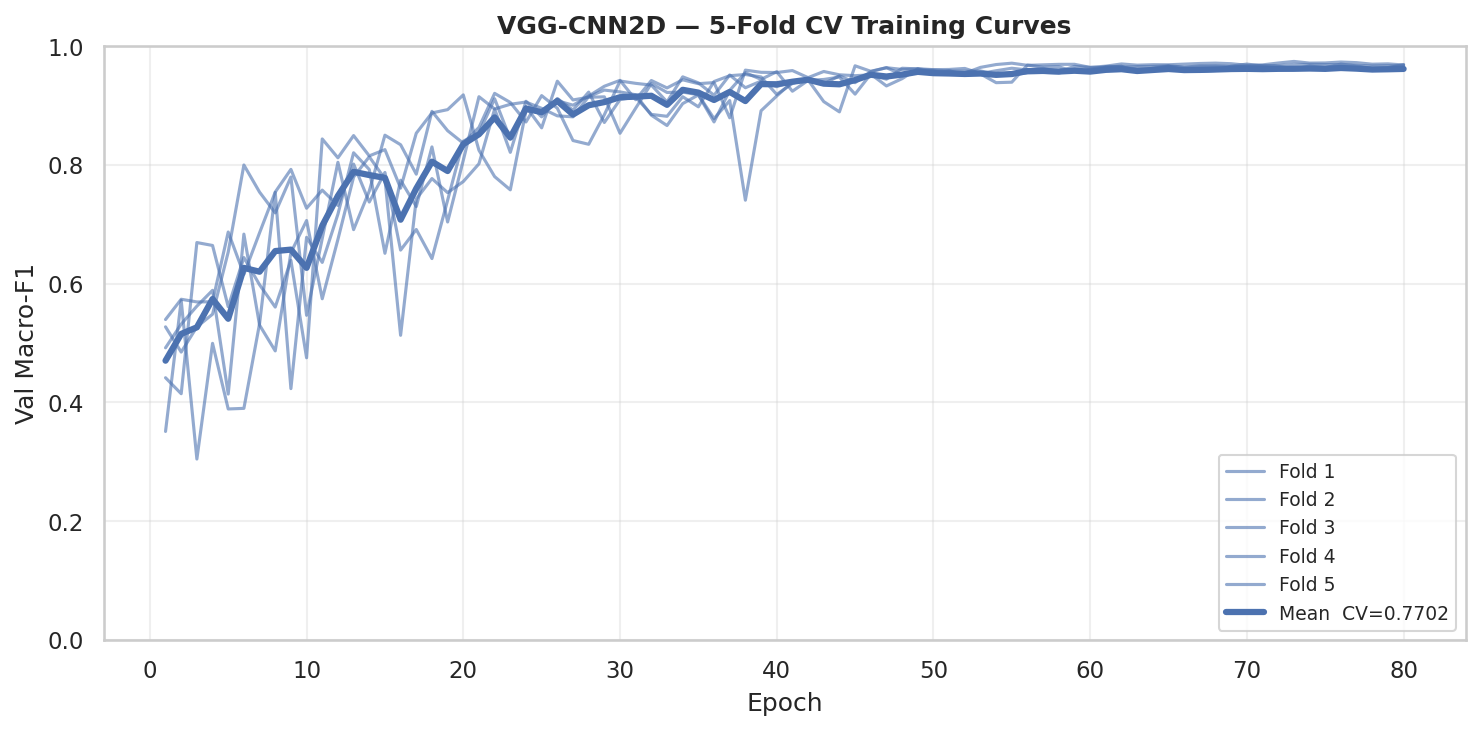

Saved: /kaggle/working/part4a/figures/vgg_training_curves.png

Creating /kaggle/working/part4a_results.zip ...
  + segments.csv            9.2 MB  ← needed by 4B, 4C
  + models/vgg_cnn2d.keras  15.9 MB
  + vgg_cv_results.json
  + logs/ (5 files)
  + figures/vgg_training_curves.png

  PART 4A COMPLETE
  VGG-CNN2D  0.7702 +/- 0.0211  95%CI [0.7440,0.7964]

  NEXT STEPS (do both after this cell completes):

  1. Upload specs_f16.npy as a new Kaggle dataset:
     File: /kaggle/working/specs_f16.npy
     Size: 5.96 GB
     (upload directly — do not zip this file)

  2. Upload part4a_results.zip as a new Kaggle dataset:
     File: /kaggle/working/part4a_results.zip  (15.3 MB)

  3. Run Part 4B and Part 4C SIMULTANEOUSLY in two
     separate Kaggle notebooks.
     Both only need specs dataset + part4a_results.zip.


In [8]:
# ============================================================
# CELL 8 ▸ VGG Training Curve Figure + Save + ZIP
# ============================================================
import matplotlib.pyplot as plt

# Training curve
fig, ax = plt.subplots(figsize=(10,5))
all_h = [m['f1_history'] for m in CV_RESULTS['VGG_CNN2D']['fold_metrics']]
for k,h in enumerate(all_h):
    ax.plot(range(1,len(h)+1), h, lw=1.5, alpha=0.6,
            color='#4C72B0', label=f'Fold {k+1}')
maxl = max(len(h) for h in all_h)
padded = [h+[h[-1]]*(maxl-len(h)) for h in all_h]
mean_h = np.mean(padded,axis=0)
ax.plot(range(1,maxl+1), mean_h, lw=3, color='#4C72B0',
        label=f'Mean  CV={vgg_sum["macro_f1_mean"]:.4f}')
ax.set_xlabel('Epoch'); ax.set_ylabel('Val Macro-F1')
ax.set_ylim(0,1); ax.grid(True,alpha=0.3); ax.legend(fontsize=9)
ax.set_title('VGG-CNN2D — 5-Fold CV Training Curves', fontweight='bold')
plt.tight_layout()
vgg_fig = os.path.join(FIG_DIR,'vgg_training_curves.png')
plt.savefig(vgg_fig); plt.show()
print(f'Saved: {vgg_fig}')

# Save JSON
def to_py(obj):
    if isinstance(obj,dict):         return {k:to_py(v) for k,v in obj.items()}
    if isinstance(obj,(list,tuple)): return [to_py(v) for v in obj]
    if isinstance(obj,np.ndarray):   return obj.tolist()
    if isinstance(obj,(np.integer,)):   return int(obj)
    if isinstance(obj,(np.floating,)):  return float(obj)
    return obj

result_json = os.path.join(OUT_DIR,'vgg_cv_results.json')
with open(result_json,'w') as f:
    json.dump(to_py(CV_RESULTS), f, indent=2)

# ── ZIP part4a_results (small files only — NOT specs_f16.npy) ─
zip_path = os.path.join(WORK_DIR,'part4a_results.zip')
print(f'\nCreating {zip_path} ...')
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as zf:
    # segments.csv
    zf.write(SEG_CSV, 'segments.csv')
    sz = os.path.getsize(SEG_CSV)/1e6
    print(f'  + segments.csv            {sz:.1f} MB  ← needed by 4B, 4C')
    # VGG model
    vgg_keras = os.path.join(MDL_DIR,'vgg_cnn2d.keras')
    if os.path.exists(vgg_keras):
        zf.write(vgg_keras, 'models/vgg_cnn2d.keras')
        print(f'  + models/vgg_cnn2d.keras  '
              f'{os.path.getsize(vgg_keras)/1e6:.1f} MB')
    # Results JSON
    zf.write(result_json, 'vgg_cv_results.json')
    print(f'  + vgg_cv_results.json')
    # Training logs
    for f in os.listdir(LOG_DIR):
        fp = os.path.join(LOG_DIR,f)
        zf.write(fp, f'logs/{f}')
    print(f'  + logs/ ({len(os.listdir(LOG_DIR))} files)')
    # Figures
    for f in sorted(os.listdir(FIG_DIR)):
        if f.endswith('.png'):
            fp = os.path.join(FIG_DIR,f)
            zf.write(fp,f'figures/{f}')
            print(f'  + figures/{f}')

zip_sz = os.path.getsize(zip_path)/1e6
s = CV_RESULTS['VGG_CNN2D']['summary']

print()
print('='*60)
print('  PART 4A COMPLETE')
print('='*60)
print(f'  VGG-CNN2D  {s["macro_f1_mean"]:.4f} +/- '
      f'{s["macro_f1_std"]:.4f}  '
      f'95%CI [{s["macro_f1_mean"]-s["macro_f1_ci95"]:.4f},'
      f'{s["macro_f1_mean"]+s["macro_f1_ci95"]:.4f}]')
print()
print('  NEXT STEPS (do both after this cell completes):')
print()
print('  1. Upload specs_f16.npy as a new Kaggle dataset:')
print(f'     File: {SPE_PATH}')
print(f'     Size: {os.path.getsize(SPE_PATH)/1e9:.2f} GB')
print('     (upload directly — do not zip this file)')
print()
print('  2. Upload part4a_results.zip as a new Kaggle dataset:')
print(f'     File: {zip_path}  ({zip_sz:.1f} MB)')
print()
print('  3. Run Part 4B and Part 4C SIMULTANEOUSLY in two')
print('     separate Kaggle notebooks.')
print('     Both only need specs dataset + part4a_results.zip.')